# Undirected Graphical Models

# Overview

This applied class has two exercises.

* **Exercise 1 (Markov networks).** Design a Markov network for a disease-spread scenario with `pgmpy`: identify the variables and edges, read off the independencies, attach factors to the cliques, convert to a factor graph and write down the Gibbs distribution.
* **Exercise 2 (Conditional random fields, debugging exercise).** Train a linear-chain CRF with `pytorch-crf` for slot filling on the ATIS corpus, compare it with a per-token baseline that shares the same emission network, and read the learned transition matrix next to the empirical one. The code is complete but contains five planted bugs that you must find and fix.

Exercise 2 mirrors Section II of this week's lecture notebook and is the Part I comparison of Assessment 2 in miniature.

In [1]:
# Libraries for Exercise 1 (Exercise 2 has its own import cell).
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

# Requires pgmpy >= 1.0, which runs on Python 3.10 or newer; pgmpy 1.x renamed
# MarkovNetwork to DiscreteMarkovNetwork and removed the old name.
from pgmpy.models import DiscreteMarkovNetwork, FactorGraph
from pgmpy.factors.discrete import DiscreteFactor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from IPython.display import display

# 1. Markov Networks

### Exercise 1: Designing a Markov Network from Scratch

A city is experiencing the spread of a contagious disease, and several factors contribute to how the disease is transmitted among the population. The weather conditions, such as temperature and humidity, play a significant role in influencing the rate at which the disease spreads. The vaccination rate within the population is crucial, as it determines how many people are protected from the disease, thus affecting its transmission. In densely populated areas, the disease tends to spread more quickly due to the higher frequency of close contact among individuals. The availability of healthcare resources, such as hospital beds and medical staff, impacts the ability of the healthcare system to manage and treat infected individuals, thereby influencing the overall disease outcomes. Additionally, the level of mobility within the city, such as daily commuting or travel, affects how fast and far the disease can spread, with increased mobility leading to a higher rate of transmission. Population density and mobility are also interconnected, as areas with higher densities tend to have more movement, which in turn can put more pressure on healthcare resources.



## Tasks:

1. Identify the random variables in this scenario.
2. Construct a Markov Network structure representing the relationships between the variables. Consider which variables are directly dependent on each other based on the given scenario. 
3. Identify the cliques in the Markov Network for factors. A clique is a fully connected subset of variables where each pair of nodes is connected by an edge. Based on the relationships between variables in the scenario, list out all the cliques and design a factor for each of them. You may add additional factors for your design. Initialize the factors randomly.
4. Convert your Markov network to a factor graph and analyze its structure.

### 1.1 Identify the random variables

#### Your analysis

- Weather (W) influences the Spread of Disease (S) since weather conditions affect how quickly diseases spread.
- Vaccination Rate (V) influences Disease Spread (S) by reducing the number of susceptible individuals.
- Population Density (D) influences the Spread of Disease (S) because higher density increases the likelihood of transmission.
- Healthcare Availability (H) influences Disease Spread (S) by impacting the ability to treat infected individuals and manage the outbreak.
- Mobility (M) influences Disease Spread (S) as higher mobility results in increased interactions and thus higher transmission rates.
- Mobility (M) is also directly related to Population Density (D), as higher population densities often lead to more mobility in the area.
- Healthcare Availability (H) and Population Density (D) are also related, as areas with higher population densities tend to put more pressure on healthcare resources.

### 1.2 Identify the edges.

#### Analysis

The undirected edges in the Markov Network would be:

- W - S
- V - S
- D - S
- H - S
- M - S
- M - D
- H - D

In [2]:
# Initialize the Markov Network model
markov_net = DiscreteMarkovNetwork()

# Add the edges representing dependencies between variables
edges = [
    ('W', 'S'),  # Weather and Disease Spread
    ('V', 'S'),  # Vaccination Rate and Disease Spread
    ('D', 'S'),  # Population Density and Disease Spread
    ('H', 'S'),  # Healthcare Availability and Disease Spread
    ('M', 'S'),  # Mobility and Disease Spread
    ('M', 'D'),  # Mobility and Population Density
    ('H', 'D')   # Healthcare and Population Density
]

# Add the edges to the Markov Network
markov_net.add_edges_from(edges)

#### Check if the graph is connected by using _nx.is_connected()_

In [3]:
# Ensure graph is connected
print(nx.is_connected(markov_net))

True


#### Visualise the Markov network

A pgmpy `DiscreteMarkovNetwork` is a `networkx.Graph`, so one `networkx` call draws it.

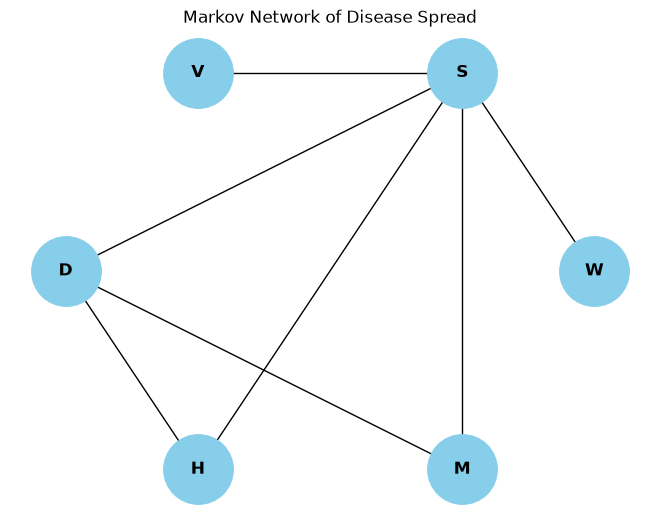

In [4]:
# Nodes on a circle, labelled; markov_net is the network built above.
nx.draw_circular(markov_net, with_labels=True, node_size=2500, node_color="skyblue", font_weight="bold")
plt.title("Markov Network of Disease Spread")
plt.show()

#### Understand the Markov network independencies

In [5]:
markov_net.get_local_independencies()

(W ⟂ D, H, M, V | S)
(V ⟂ D, H, M, W | S)
(D ⟂ V, W | H, M, S)
(H ⟂ M, V, W | D, S)
(M ⟂ H, V, W | D, S)

### 1.3 Identify the factors for your Markov Network and add them to your Markov network.

In [6]:
phi_W_S = DiscreteFactor(variables=['W', 'S'], cardinality=[2, 2], values=np.random.rand(4))

# Potential function for (V, S)
phi_V_S = DiscreteFactor(variables=['V', 'S'], cardinality=[2, 2], values=np.random.rand(4))

# Potential function for (M, D, S)
phi_M_D_S = DiscreteFactor(variables=['M','D', 'S'], cardinality=[2, 2, 2], values=np.random.rand(8))

# Potential function for (H, D, S)
phi_H_D_S = DiscreteFactor(variables=['H','D', 'S'], cardinality=[2, 2, 2], values=np.random.rand(8))

# Potential function for W
phi_W = DiscreteFactor(variables=['W'], cardinality=[2], values=np.random.rand(2))

# Potential function for V
phi_V = DiscreteFactor(variables=['V'], cardinality=[2], values=np.random.rand(2))

# Potential function for H
phi_H = DiscreteFactor(variables=['H'], cardinality=[2], values=np.random.rand(2))

phi_M = DiscreteFactor(variables=['M'], cardinality=[2], values=np.random.rand(2))

markov_net.add_factors(phi_W_S, phi_V_S, phi_M_D_S, phi_H_D_S, phi_W,phi_V,phi_H, phi_M)

#### Check your model

In [7]:
markov_net.check_model()

True

#### 1.4 Convert your Markov network to a factor graph and write down the Gibbs distribution.

In [8]:
factor_graph = markov_net.to_factor_graph()
print(factor_graph.edges())

[('W', 'phi_W_S'), ('W', 'phi_W'), ('S', 'phi_W_S'), ('S', 'phi_V_S'), ('S', 'phi_M_D_S'), ('S', 'phi_H_D_S'), ('V', 'phi_V_S'), ('V', 'phi_V'), ('D', 'phi_M_D_S'), ('D', 'phi_H_D_S'), ('H', 'phi_H_D_S'), ('H', 'phi_H'), ('M', 'phi_M_D_S'), ('M', 'phi_M')]


In [9]:
def visualize_factor_graph(f_graph):
    G = nx.Graph()
    variable_nodes = set([x for factor in f_graph.get_factors() for x in factor.scope()]) #f_graph.get_variable_nodes()
    factor_nodes = set(f_graph.nodes()) - variable_nodes
    G.add_nodes_from(variable_nodes, bipartite=0)  # Variable nodes
    G.add_nodes_from(factor_nodes, bipartite=1) 
    # Add edges to the graph
    G.add_edges_from(f_graph.edges())
    # Step 4: Plot the graph
    pos = nx.shell_layout(G)  # Layout for positioning the nodes
    plt.figure(figsize=(15, 8))

    # Draw nodes
    nx.draw_networkx_nodes(G, pos, nodelist=variable_nodes, node_color='lightblue', node_size=2000, label='Variables')
    nx.draw_networkx_nodes(G, pos, nodelist=factor_nodes, node_color='lightgreen', node_shape='s', node_size=3000, label='Factors')

    # Draw edges
    nx.draw_networkx_edges(G, pos, edgelist=f_graph.edges())

    # Draw labels for nodes
    nx.draw_networkx_labels(G, pos, font_size=12, font_color='black')

    # Show plot
    plt.title('Factor Graph', fontsize=15, fontweight='bold')
    plt.axis('off')  # Turn off the axes
    plt.show()

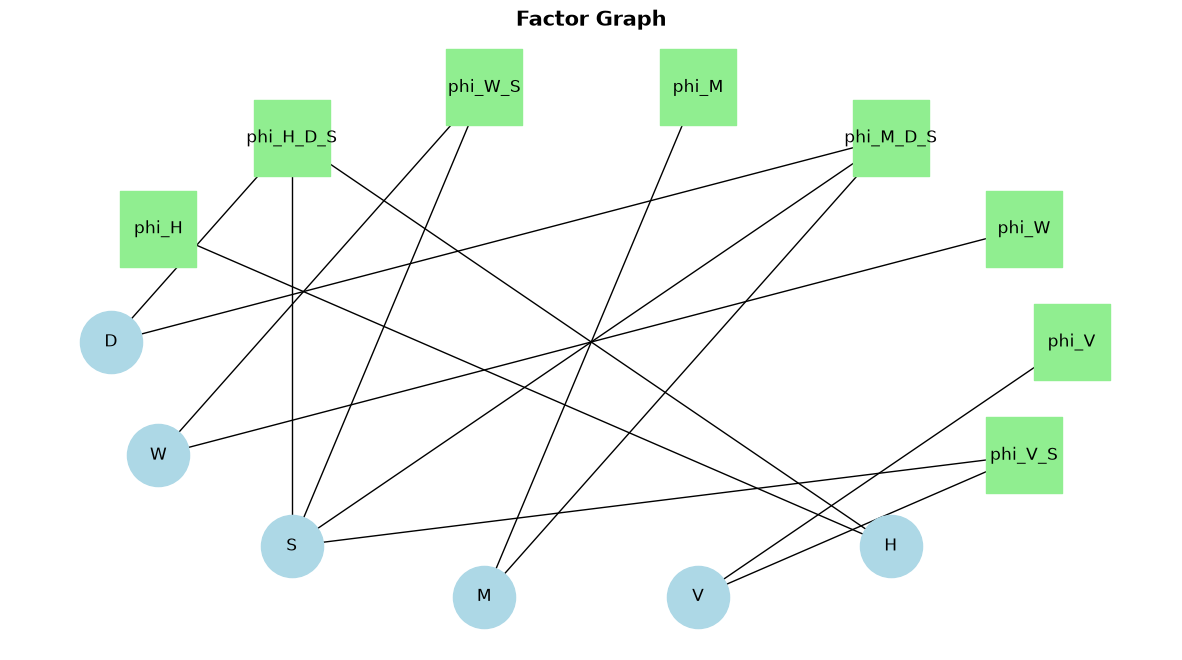

In [10]:
visualize_factor_graph(factor_graph)

### 1.5 Write down the Gibbs distribution for the joint distribution $P(W,V,D,H,M,S)$

The joint probability distribution $P(W,V,D,H,M,S)$ is expressed as:

\begin{align*}
P(W,V,D,H,M,S) &= \frac{1}{Z} \prod_{c \in C} \phi_c(X_c)\\
& = \frac{1}{Z} \phi(W,S) \cdot \phi(V,S) \cdot \phi(M, D,S) \cdot \phi(H,D, S) \cdot \phi(V) \cdot \phi (W) \cdot \phi(M) \cdot \phi(H)
\end{align*}


#### Summary: two general approaches to design a Markov network.

**Approach 1**
1. Identify relevant random variables.
2. Identify relevant interactions between random variables and add an edge between a pair of variables if they have direct influence to each other.
3. Identify all maximal cliques from the undirected graph and design a factor for each of the cliques, which involves all variables of that clique.
4. Add additional factors based on your understanding of the problem and the dataset.

**Approach 2**
1. Design a Bayesian network first if it is easy to tell the direction of influence for most pairs of random variables with direct interactions.
2. Convert the Bayesian network to a Markov network using moralization.

# 2. Conditional Random Fields for Slot Filling (Debugging Exercise)

## The task: slot filling on ATIS

ATIS (Airline Travel Information System) is a collection of spoken requests to a flight-booking system. **Slot filling** labels every word of a request with the piece of information (the *slot*) it carries, so that a downstream system can fill in a query such as `flights(from=boston, to=denver, date=thursday)`.

Slots are written with the **BIO scheme**: `B-slot` marks the first word of a slot value, `I-slot` marks each following word of the same value, and `O` marks words that fill no slot. An example from the training set:

| word | i | want | to | fly | from | boston | at | 838 | am | and | arrive | in | denver |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| tag | O | O | O | O | O | B-fromloc.city_name | O | B-depart_time.time | I-depart_time.time | O | O | O | B-toloc.city_name |

Two things make this a sequence-labelling problem rather than a word-by-word classification problem:

* **Neighbouring words decide the tag.** *boston* is a departure city because it follows *from*; the same word after *to* would be `B-toloc.city_name`.
* **Neighbouring tags constrain each other.** `I-depart_time.time` is only legal directly after `B-depart_time.time` or another `I-depart_time.time`. A tagger that labels each word independently can output `B-fromloc.city_name I-toloc.city_name`, which no human annotator would.

The dataset has 4,978 training and 893 test requests, about 120 distinct BIO tags, and a vocabulary of roughly 900 words. We use the version distributed with the JointSLU repository (Hakkani-Tür et al., 2016), which stores one request per line as `words TAB tags`; the words are wrapped in `BOS ... EOS` and the last tag position holds the *intent* of the request, which we ignore here.

## The models

Following the lecture, we build **one emission network and decode it in two ways**:

1. **Per-token baseline.** `Embedding → window layer → Linear` scores every tag for every word and takes the arg-max independently at each position. The window layer is a `Linear` applied to the embeddings of the word and its two neighbours, implemented as `nn.Conv1d(kernel_size=3)`.
2. **Linear-chain CRF.** The same emission scores plus a learned transition matrix from `torchcrf.CRF`, trained jointly with Adam and decoded with Viterbi.

We then read the learned transition matrix next to the empirical one counted from the training tags, exactly as in Activity II of the lecture.

## How this exercise works

The code below is a complete pipeline, but **it contains exactly five bugs**. All five are mistakes that beginners make routinely; some crash with a traceback, others run silently and produce wrong numbers. Your job is to run the notebook from top to bottom, find each bug, fix it, and record it in the bug log at the end of the section.

A few habits that catch most bugs:

* Read a traceback from the **bottom**: the last line names the error, the line above it points to the code that raised it.
* When a layer complains about shapes, `print(x.shape)` immediately before the call and compare with the shape the layer's documentation expects.
* Check **invariants**: a negative log-likelihood is never negative; running the same evaluation twice gives the same number; each row of a conditional probability table sums to one; the number of predictions equals the number of gold labels.
* When a model trains without errors but scores far below a simple baseline, suspect the objective or the evaluation before the architecture.

Install the one extra dependency if needed: `pip install pytorch-crf` (imported as `torchcrf`).

In [11]:
import os
import random
import time
import urllib.request
from collections import Counter
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from torchcrf import CRF
from sklearn.metrics import f1_score

# Same OpenMP workaround as in the Exercise 1 import cell (harmless if already set).
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

# Special tokens shared by the word and tag vocabularies.
PAD = "<pad>"  # fills the unused positions of shorter sentences in a batch
UNK = "<unk>"  # stands in for words never seen in training

SEED = 5149
DATA_DIR = Path("data")
ATIS_URL = "https://raw.githubusercontent.com/yvchen/JointSLU/master/data/"


def set_seed(seed: int) -> None:
    """Seed every random number generator we use, so that runs are repeatable."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


@dataclass(frozen=True)
class Config:
    """All hyperparameters in one place; frozen so nothing changes them by accident."""
    embedding_dim: int = 64     # size of each word vector
    hidden_dim: int = 128       # output size of the window layer
    window: int = 3             # number of consecutive words the window layer sees
    dropout: float = 0.3        # dropout on the embeddings
    batch_size: int = 32
    epochs: int = 6
    learning_rate: float = 2e-3


cfg = Config()
set_seed(SEED)
pd.set_option("display.max_columns", 60)  # sentence tables have one column per word
print(cfg)

Config(embedding_dim=64, hidden_dim=128, window=3, dropout=0.3, batch_size=32, epochs=6, learning_rate=0.002)


### 2.1 Load the data and look at an example

`download_atis` fetches each split once and caches it under `data/`. If your machine has no internet access, download `atis.train.w-intent.iob` and `atis.test.w-intent.iob` from the URL above by hand and save them as `data/atis.train.iob` and `data/atis.test.iob`.

In [12]:
def download_atis(split: str) -> Path:
    """Return the local path of one ATIS split, downloading it on first use."""
    DATA_DIR.mkdir(exist_ok=True)
    target = DATA_DIR / f"atis.{split}.iob"
    if not target.exists():
        urllib.request.urlretrieve(f"{ATIS_URL}atis.{split}.w-intent.iob", target)
    return target


def read_atis(path: Path) -> list[tuple[list[str], list[str]]]:
    """Parse an ATIS file into (words, tags) pairs.

    Each line is ``BOS w_1 ... w_n EOS<TAB>O t_1 ... t_n intent``.  The BOS/EOS
    markers and the intent label (aligned with EOS) are stripped, so every
    returned word list is exactly as long as its tag list.
    """
    sentences = []
    with open(path, encoding="utf-8") as handle:
        for line in handle:
            if not line.strip():
                continue
            word_part, tag_part = line.rstrip("\n").split("\t")
            words, tags = word_part.split(), tag_part.split()
            assert words[0] == "BOS" and words[-1] == "EOS", line
            assert len(words) == len(tags), line
            sentences.append((words[1:-1], tags[1:-1]))
    return sentences


train_sentences = read_atis(download_atis("train"))
test_sentences = read_atis(download_atis("test"))
print(f"{len(train_sentences)} training and {len(test_sentences)} test requests")

4978 training and 893 test requests


In [13]:
def show_sentence(words: list[str], *tag_rows: tuple[str, list[str]]) -> pd.DataFrame:
    """Display a sentence with one or more rows of tags aligned under the words."""
    table = {"word": words}
    for name, tags in tag_rows:
        table[name] = tags
    return pd.DataFrame(table).T


# The first training request: every slot value starts with a B- tag and
# continues with I- tags of the same type.
words, tags = train_sentences[0]
show_sentence(words, ("gold", tags))

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
word,i,want,to,fly,from,boston,at,838,am,and,arrive,in,denver,at,1110,in,the,morning
gold,O,O,O,O,O,B-fromloc.city_name,O,B-depart_time.time,I-depart_time.time,O,O,O,B-toloc.city_name,O,B-arrive_time.time,O,O,B-arrive_time.period_of_day


In [14]:
# Dataset statistics: tag inventory and the most frequent tags.
tag_counts = Counter(tag for _, tags in train_sentences for tag in tags)
word_counts = Counter(word for words, _ in train_sentences for word in words)
lengths = [len(words) for words, _ in train_sentences]

print(f"{len(tag_counts)} distinct tags, {len(word_counts)} distinct words")
print(f"sentence length: mean {np.mean(lengths):.1f}, max {max(lengths)}")
print(f"'O' covers {tag_counts['O'] / sum(tag_counts.values()):.1%} of all tokens\n")
pd.Series(tag_counts).sort_values(ascending=False).head(12).to_frame("count")

121 distinct tags, 898 distinct words
sentence length: mean 11.3, max 46
'O' covers 63.5% of all tokens



,count
O,35669
B-toloc.city_name,4343
B-fromloc.city_name,4326
I-toloc.city_name,1099
B-depart_date.day_name,889
B-airline_name,701
I-fromloc.city_name,691
B-depart_time.period_of_day,593
I-airline_name,421
B-depart_date.day_number,395


### 2.2 Vocabularies and tensors

Neural networks work on integer ids, not strings. We build one vocabulary for words and one for tags **from the training data only**. The word vocabulary reserves id 0 for `<pad>` and id 1 for `<unk>`; the tag vocabulary reserves id 0 for `<pad>`.

Six test tokens carry tags that never occur in training (for example `B-booking_class`). The model cannot predict a tag it has never seen, so we map those gold tags to `O`. This is different from unseen *words*, which must still be tagged and therefore need the `<unk>` id.

In [15]:
def build_vocab(sequences: list[list[str]], add_unk: bool) -> dict[str, int]:
    """Map every symbol in ``sequences`` to an integer id, with special ids first.

    Symbols are sorted so that the mapping does not depend on data order.
    """
    specials = [PAD, UNK] if add_unk else [PAD]
    symbols = sorted({symbol for seq in sequences for symbol in seq})
    return {symbol: index for index, symbol in enumerate(specials + symbols)}


word2idx = build_vocab([words for words, _ in train_sentences], add_unk=True)
tag2idx = build_vocab([tags for _, tags in train_sentences], add_unk=False)
idx2tag = {index: tag for tag, index in tag2idx.items()}  # inverse mapping for printing

print(f"{len(word2idx)} word ids (incl. {PAD}, {UNK}); {len(tag2idx)} tag ids (incl. {PAD})")


def encode(sentences: list[tuple[list[str], list[str]]]) -> list[tuple[list[int], list[int]]]:
    """Convert (words, tags) string pairs into (word_ids, tag_ids) integer pairs.

    Words outside the training vocabulary map to ``UNK``; tags outside the
    training tag set map to ``O`` (see the note above).
    """
    encoded = []
    for words, tags in sentences:
        word_ids = [word2idx.get(word, word2idx[UNK]) for word in words]
        tag_ids = [tag2idx.get(tag, tag2idx["O"]) for tag in tags]
        encoded.append((word_ids, tag_ids))
    return encoded


train_encoded = encode(train_sentences)
test_encoded = encode(test_sentences)
print("first encoded request:", train_encoded[0][0][:8], "...")

900 word ids (incl. <pad>, <unk>); 122 tag ids (incl. <pad>)
first encoded request: [441, 857, 807, 393, 407, 237, 214, 147] ...


Sentences have different lengths, so a batch is padded to the length of its longest sentence. The **mask** records which positions hold real words (`True`) and which are padding (`False`). Every later step that touches the labels (the loss, the CRF, the evaluation) must respect this mask.

In [16]:
class SlotDataset(Dataset):
    """Wrap the encoded sentences so that a DataLoader can batch them."""

    def __init__(self, encoded: list[tuple[list[int], list[int]]]):
        self.items = encoded

    def __len__(self) -> int:
        return len(self.items)

    def __getitem__(self, index: int) -> tuple[torch.Tensor, torch.Tensor]:
        word_ids, tag_ids = self.items[index]
        return torch.tensor(word_ids), torch.tensor(tag_ids)


def collate(batch: list[tuple[torch.Tensor, torch.Tensor]]) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
    """Pad a list of (word_ids, tag_ids) pairs into three tensors of shape (batch, length).

    Returns word ids, tag ids and a boolean mask that is True on real tokens.
    """
    words, tags = zip(*batch)
    padded_words = nn.utils.rnn.pad_sequence(words, batch_first=True, padding_value=word2idx[PAD])
    padded_tags = nn.utils.rnn.pad_sequence(tags, batch_first=True, padding_value=tag2idx[PAD])
    mask = padded_words != word2idx[PAD]
    return padded_words, padded_tags, mask


train_loader = DataLoader(SlotDataset(train_encoded), batch_size=cfg.batch_size, shuffle=True, collate_fn=collate)
test_loader = DataLoader(SlotDataset(test_encoded), batch_size=cfg.batch_size, shuffle=False, collate_fn=collate)

# Inspect one batch: shapes and the mask of the first two sentences.
words_batch, tags_batch, mask_batch = next(iter(train_loader))
print("words", tuple(words_batch.shape), "tags", tuple(tags_batch.shape), "mask", tuple(mask_batch.shape))
print("real tokens per sentence:", mask_batch.sum(dim=1)[:8].tolist())

words (32, 42) tags (32, 42) mask (32, 42)
real tokens per sentence: [23, 11, 20, 16, 7, 14, 9, 9]


### 2.3 The emission network and the two decoders

`EmissionNetwork` turns word ids into a score for every tag at every position. `SlotTagger` wraps it with either an independent arg-max per position (the baseline) or a `torchcrf.CRF` layer, which adds a learned transition score for every pair of consecutive tags and decodes with Viterbi.

`CRF.forward(emissions, tags, mask)` returns the **log-likelihood** of the gold tag sequence. `CRF.decode(emissions, mask)` returns the best tag sequence of each sentence as a list of lists, already trimmed to the true lengths.

In [17]:
class EmissionNetwork(nn.Module):
    """Embedding -> dropout -> window layer -> Linear, producing one score per tag per word.

    The window layer is a Conv1d with kernel size ``cfg.window``: a Linear layer
    applied to the concatenated embeddings of a word and its neighbours.
    """

    def __init__(self, vocab_size: int, num_tags: int, cfg: Config):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, cfg.embedding_dim, padding_idx=0)
        self.dropout = nn.Dropout(cfg.dropout)
        # Conv1d expects (batch, channels, length) and returns (batch, out_channels, length).
        self.window = nn.Conv1d(cfg.embedding_dim, cfg.hidden_dim, kernel_size=cfg.window, padding=cfg.window // 2)
        self.output = nn.Linear(cfg.hidden_dim, num_tags)

    def forward(self, word_ids: torch.Tensor) -> torch.Tensor:
        """Map word ids (batch, length) to emission scores (batch, length, num_tags)."""
        embedded = self.dropout(self.embedding(word_ids))     # (batch, length, embedding_dim)
        hidden = torch.relu(self.window(embedded.transpose(1, 2)))  # (batch, hidden_dim, length)
        return self.output(hidden.transpose(1, 2))             # (batch, length, num_tags)


class SlotTagger(nn.Module):
    """The emission network decoded either per token (baseline) or with a linear-chain CRF."""

    def __init__(self, vocab_size: int, num_tags: int, cfg: Config, use_crf: bool):
        super().__init__()
        self.emission_network = EmissionNetwork(vocab_size, num_tags, cfg)
        self.crf = CRF(num_tags, batch_first=True) if use_crf else None

    def loss(self, word_ids: torch.Tensor, tag_ids: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
        """Mean negative log-likelihood of the gold tags over the batch."""
        emissions = self.emission_network(word_ids)
        if self.crf is None:
            # Baseline: cross-entropy over real tokens only; padding is excluded by the mask.
            return F.cross_entropy(emissions[mask], tag_ids[mask])
        # CRF: the layer returns the log-likelihood of the gold sequence.
        return -self.crf(emissions, tag_ids, mask=mask, reduction="mean")

    @torch.no_grad()
    def decode(self, word_ids: torch.Tensor, mask: torch.Tensor) -> list[list[int]]:
        """Best tag ids for each sentence, trimmed to its real length."""
        emissions = self.emission_network(word_ids)
        if self.crf is None:
            best = emissions.argmax(dim=-1)                     # independent arg-max per position
            return [best[i, mask[i]].tolist() for i in range(best.size(0))]
        return self.crf.decode(emissions, mask=mask)           # Viterbi over emissions + transitions


# Smoke test: the network must produce one score per tag for every position of the batch.
smoke_model = SlotTagger(len(word2idx), len(tag2idx), cfg, use_crf=True)
smoke_scores = smoke_model.emission_network(words_batch)
print("emission scores", tuple(smoke_scores.shape), "expected", (*words_batch.shape, len(tag2idx)))
print("decoded lengths match mask:", all(len(p) == int(m.sum()) for p, m in zip(smoke_model.decode(words_batch, mask_batch), mask_batch)))

emission scores (32, 42, 122) expected (32, 42, 122)
decoded lengths match mask: True


### 2.4 Evaluation

Slot filling is scored at two levels. **Token accuracy** and **macro F1** treat each word on its own, as in the assessment. **Span F1** gives credit only when a whole slot value (type, start and end) is recovered exactly; it is the standard CoNLL-style measure for slot filling and is the one that rewards consistent BIO sequences.

In [18]:
def bio_spans(tags: list[str]) -> set[tuple[str, int, int]]:
    """Extract (slot type, start, end) spans from a BIO tag sequence; end is exclusive.

    An ``I-`` tag whose type differs from the open span starts a new span, which
    is the usual CoNLL convention for malformed sequences.
    """
    spans, start, kind = set(), None, None
    for position, tag in enumerate(tags + ["O"]):             # sentinel closes the last span
        opens_new = tag.startswith("B-") or (tag.startswith("I-") and tag[2:] != kind)
        if (opens_new or tag == "O") and kind is not None:
            spans.add((kind, start, position))
            start, kind = None, None
        if opens_new:
            start, kind = position, tag[2:]
    return spans


def span_f1(gold_sequences: list[list[str]], predicted_sequences: list[list[str]]) -> float:
    """Micro-averaged F1 over exact slot spans."""
    true_positives = false_positives = false_negatives = 0
    for gold, predicted in zip(gold_sequences, predicted_sequences):
        gold_spans, predicted_spans = bio_spans(gold), bio_spans(predicted)
        true_positives += len(gold_spans & predicted_spans)
        false_positives += len(predicted_spans - gold_spans)
        false_negatives += len(gold_spans - predicted_spans)
    precision = true_positives / max(true_positives + false_positives, 1)
    recall = true_positives / max(true_positives + false_negatives, 1)
    return 2 * precision * recall / max(precision + recall, 1e-12)


@torch.no_grad()
def predict(model: SlotTagger, loader: DataLoader) -> tuple[list[list[str]], list[list[str]]]:
    """Return gold and predicted tag strings for every sentence in ``loader``."""
    model.eval()  # switch dropout off; evaluation must be deterministic
    gold_sequences, predicted_sequences = [], []
    for word_ids, tag_ids, mask in loader:
        for gold_ids, predicted_ids, sentence_mask in zip(tag_ids, model.decode(word_ids, mask), mask):
            gold_sequences.append([idx2tag[i] for i in gold_ids[sentence_mask].tolist()])
            predicted_sequences.append([idx2tag[i] for i in predicted_ids])
    return gold_sequences, predicted_sequences


def evaluate(model: SlotTagger, loader: DataLoader) -> dict[str, float]:
    """Token accuracy, token-level macro F1 and span F1 on ``loader``."""
    gold_sequences, predicted_sequences = predict(model, loader)
    gold_flat = [tag for sentence in gold_sequences for tag in sentence]
    predicted_flat = [tag for sentence in predicted_sequences for tag in sentence]
    assert len(gold_flat) == len(predicted_flat), "one prediction per gold token"
    return {
        "token_acc": float(np.mean([g == p for g, p in zip(gold_flat, predicted_flat)])),
        "macro_f1": f1_score(gold_flat, predicted_flat, average="macro", zero_division=0),
        "span_f1": span_f1(gold_sequences, predicted_sequences),
    }


# Unit test for the span extractor on a hand-made sequence.
assert bio_spans(["O", "B-x", "I-x", "O", "B-y", "I-x"]) == {("x", 1, 3), ("y", 4, 5), ("x", 5, 6)}
print("bio_spans ok")

bio_spans ok


### 2.5 Train both models

Both models share the emission architecture and hyperparameters; only the decoder differs. The CRF is slower per epoch because the forward algorithm loops over the sequence.

In [19]:
def train_model(model: SlotTagger, loader: DataLoader, cfg: Config) -> list[float]:
    """Train ``model`` with Adam and return the mean training loss per epoch."""
    optimiser = torch.optim.Adam(model.parameters(), lr=cfg.learning_rate)
    history = []
    for epoch in range(1, cfg.epochs + 1):
        model.train()                       # dropout on
        epoch_loss, start = 0.0, time.time()
        for word_ids, tag_ids, mask in loader:
            optimiser.zero_grad()           # gradients accumulate unless cleared
            loss = model.loss(word_ids, tag_ids, mask)
            loss.backward()
            optimiser.step()
            epoch_loss += loss.item()
        history.append(epoch_loss / len(loader))
        print(f"epoch {epoch}: mean loss {history[-1]:.4f}  ({time.time() - start:.0f}s)")
    return history


results = {}
models = {}
for name, use_crf in [("baseline", False), ("crf", True)]:
    print(f"--- {name} ---")
    set_seed(SEED)                          # same initialisation and batch order for both
    models[name] = SlotTagger(len(word2idx), len(tag2idx), cfg, use_crf)
    train_model(models[name], train_loader, cfg)
    results[name] = evaluate(models[name], test_loader)

pd.DataFrame(results).T.round(4)

--- baseline ---
epoch 1: mean loss 0.9129  (1s)
epoch 2: mean loss 0.2873  (1s)
epoch 3: mean loss 0.1944  (1s)
epoch 4: mean loss 0.1567  (1s)
epoch 5: mean loss 0.1361  (1s)
epoch 6: mean loss 0.1206  (1s)
--- crf ---
epoch 1: mean loss 9.9973  (12s)
epoch 2: mean loss 2.9556  (13s)
epoch 3: mean loss 1.9261  (11s)
epoch 4: mean loss 1.4603  (11s)
epoch 5: mean loss 1.1992  (10s)
epoch 6: mean loss 1.0117  (10s)


,token_acc,macro_f1,span_f1
baseline,0.9471,0.5904,0.8416
crf,0.9585,0.6165,0.8980


Before reading the numbers, run the evaluation a second time. Evaluation is a pure function of the fitted model and the test set, so the two tables must be identical.

In [20]:
pd.DataFrame({name: evaluate(model, test_loader) for name, model in models.items()}).T.round(4)

,token_acc,macro_f1,span_f1
baseline,0.9471,0.5904,0.8416
crf,0.9585,0.6165,0.8980


### 2.6 Where do the two decoders disagree?

The lecture's Activity II compared the per-token baseline with the CRF on two sentences and on per-tag F1. We do the same here: first two test requests on which the decoders differ, then the gain per tag for the most frequent tags.

In [21]:
gold_test, baseline_pred = predict(models["baseline"], test_loader)
_, crf_pred = predict(models["crf"], test_loader)

# Indices of the test requests on which the two decoders disagree.
disagreements = [i for i, (b, c) in enumerate(zip(baseline_pred, crf_pred)) if b != c]
print(f"{len(disagreements)} of {len(gold_test)} test requests are tagged differently\n")

for index in disagreements[:2]:
    words, _ = test_sentences[index]
    display(show_sentence(words, ("gold", gold_test[index]), ("baseline", baseline_pred[index]), ("crf", crf_pred[index])))

168 of 893 test requests are tagged differently



,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
word,i,would,like,to,find,a,flight,from,charlotte,to,las,vegas,that,makes,a,stop,in,st.,louis
gold,O,O,O,O,O,O,O,O,B-fromloc.city_name,O,B-toloc.city_name,I-toloc.city_name,O,O,O,O,O,B-stoploc.city_name,I-stoploc.city_name
baseline,O,O,O,O,O,O,O,O,B-fromloc.city_name,O,B-toloc.city_name,I-toloc.city_name,O,O,O,O,O,B-stoploc.city_name,I-toloc.city_name
crf,O,O,O,O,O,O,O,O,B-fromloc.city_name,O,B-toloc.city_name,I-toloc.city_name,O,O,O,O,O,B-stoploc.city_name,I-stoploc.city_name


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
word,on,april,first,i,need,a,ticket,from,tacoma,to,san,jose,departing,before,7,am
gold,O,B-depart_date.month_name,B-depart_date.day_number,O,O,O,O,O,B-fromloc.city_name,O,B-toloc.city_name,I-toloc.city_name,O,B-depart_time.time_relative,B-depart_time.time,I-depart_time.time
baseline,O,B-depart_date.month_name,B-depart_date.day_number,O,O,O,O,O,B-fromloc.city_name,O,B-toloc.city_name,I-toloc.city_name,O,B-arrive_time.time_relative,B-arrive_time.time,I-arrive_time.time
crf,O,B-depart_date.month_name,B-depart_date.day_number,O,O,O,O,O,B-fromloc.city_name,O,B-toloc.city_name,I-toloc.city_name,O,B-depart_time.time_relative,B-depart_time.time,I-depart_time.time


In [22]:
def per_tag_f1(gold_sequences: list[list[str]], predicted_sequences: list[list[str]], tags: list[str]) -> np.ndarray:
    """Token-level F1 for each tag in ``tags``, in that order."""
    gold_flat = [tag for sentence in gold_sequences for tag in sentence]
    predicted_flat = [tag for sentence in predicted_sequences for tag in sentence]
    return f1_score(gold_flat, predicted_flat, labels=tags, average=None, zero_division=0)


frequent_tags = [tag for tag, _ in tag_counts.most_common(16)]
per_tag = pd.DataFrame({
    "train_count": [tag_counts[tag] for tag in frequent_tags],
    "baseline_f1": per_tag_f1(gold_test, baseline_pred, frequent_tags),
    "crf_f1": per_tag_f1(gold_test, crf_pred, frequent_tags),
}, index=frequent_tags)
per_tag["gain"] = per_tag["crf_f1"] - per_tag["baseline_f1"]
per_tag.sort_values("gain", ascending=False).round(3)

,train_count,baseline_f1,crf_f1,gain
I-fromloc.city_name,691,0.887,0.972,0.085
I-toloc.city_name,1099,0.885,0.933,0.048
B-flight_mod,329,0.917,0.936,0.020
I-airline_name,421,0.963,0.977,0.014
B-fromloc.city_name,4326,0.974,0.985,0.012
B-depart_date.day_name,889,0.963,0.970,0.007
B-depart_time.time,369,0.818,0.824,0.005
B-depart_time.period_of_day,593,0.911,0.911,0.001
O,35669,0.992,0.992,0.000
B-cost_relative,344,0.972,0.972,0.000


### 2.7 Learned versus empirical transitions

`model.crf.transitions[i, j]` is the learned score for moving from tag `i` to tag `j`. The empirical counterpart is the conditional probability $P(y_t = j \mid y_{t-1} = i)$ estimated by counting consecutive tag pairs in the training data, so **each row of the empirical matrix must sum to one** (a tag that only ever ends a request has no successor and keeps an all-zero row). We compute both matrices over all tags, check the invariant, and plot $\log P$ next to the learned scores for the twelve most frequent tags, with the `B-` and `I-` tag of each slot type placed side by side.

In [23]:
def empirical_transitions(sentences: list[tuple[list[str], list[str]]], tags: list[str]) -> pd.DataFrame:
    """Estimate P(next tag | current tag) from consecutive tag pairs, restricted to ``tags``."""
    index = {tag: i for i, tag in enumerate(tags)}
    counts = np.zeros((len(tags), len(tags)))
    for _, tag_sequence in sentences:
        for previous, current in zip(tag_sequence[:-1], tag_sequence[1:]):
            if previous in index and current in index:
                counts[index[previous], index[current]] += 1
    # Normalise each row (the current tag) so that it is a distribution over the next tag.
    probs = counts / np.maximum(counts.sum(axis=1, keepdims=True), 1)
    return pd.DataFrame(probs, index=tags, columns=tags)


def learned_transitions(model: SlotTagger, tags: list[str]) -> pd.DataFrame:
    """Learned CRF transition scores restricted to ``tags`` (rows: from, columns: to)."""
    ids = [tag2idx[tag] for tag in tags]
    scores = model.crf.transitions.detach().numpy()[np.ix_(ids, ids)]
    return pd.DataFrame(scores, index=tags, columns=tags)


all_tags = [idx2tag[index] for index in range(1, len(idx2tag))]   # every real tag; id 0 is <pad>
empirical_full = empirical_transitions(train_sentences, all_tags)
learned_full = learned_transitions(models["crf"], all_tags)

# Invariant: every row is a distribution, so it sums to 1. The only exception is a tag
# that never has a successor in training (it only ever ends a request): its row stays 0.
print("how many rows sum to each value:")
print(empirical_full.sum(axis=1).round(6).value_counts().sort_index())

# Twelve most frequent tags for the plots, ordered so that B- and I- of a slot type are adjacent, O first.
shown_tags = sorted([tag for tag, _ in tag_counts.most_common(12)], key=lambda t: (t != "O", t[2:], t))
empirical = empirical_full.loc[shown_tags, shown_tags]
learned = learned_full.loc[shown_tags, shown_tags]

how many rows sum to each value:
0.0      9
1.0    112
Name: count, dtype: int64


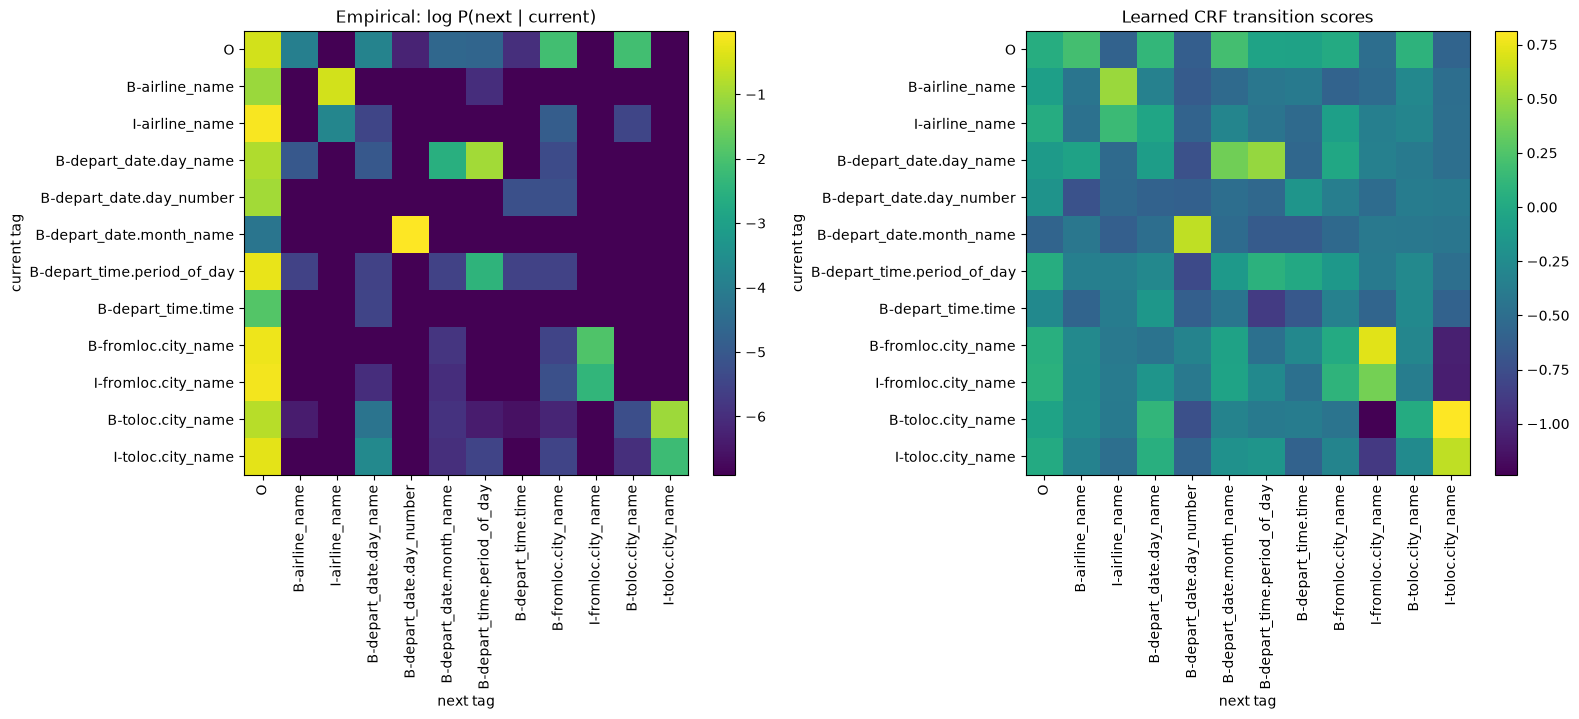

In [24]:
def plot_transition_heatmaps(empirical: pd.DataFrame, learned: pd.DataFrame) -> None:
    """Side-by-side heatmaps of log empirical probabilities and learned CRF scores."""
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    panels = [
        (np.log(empirical.values + 1e-3), "Empirical: log P(next | current)"),
        (learned.values, "Learned CRF transition scores"),
    ]
    for axis, (matrix, title) in zip(axes, panels):
        image = axis.imshow(matrix, cmap="viridis")
        axis.set_xticks(range(len(learned.columns)), learned.columns, rotation=90)
        axis.set_yticks(range(len(learned.index)), learned.index)
        axis.set_xlabel("next tag")
        axis.set_ylabel("current tag")
        axis.set_title(title)
        fig.colorbar(image, ax=axis, fraction=0.046)
    fig.tight_layout()
    plt.show()


plot_transition_heatmaps(empirical, learned)

### 2.8 Reading the results

Answer in the cell below, with reference to the tables and heatmaps above.

1. Which tags gained most from the transition layer, and why did the `B-` tags gain less than the `I-` tags?
2. In the two example requests, which baseline errors did the CRF repair, and which errors did it leave (or introduce)?
3. Which transitions does the learned matrix favour and which does it suppress? Are any of the suppressed transitions impossible under BIO (for example `O → I-x`, or `B-x → I-y` with `x ≠ y`)?
4. Where do the two matrices disagree? Explain the disagreement from the fact that transition scores are *added* to emission scores before decoding, whereas the empirical matrix is a probability on its own.

#### Model answers for 2.8

The numbers below are from the reference run (`SEED = 5149`, six epochs, CPU). Yours will differ slightly; the pattern should not. Reference scores: baseline token accuracy 0.947, macro F1 0.590, span F1 0.842; CRF 0.958, 0.609 and 0.896. The CRF's advantage is largest on span F1, the measure that rewards whole, well-formed slot values.

1. **Which tags gained most.** The largest gains are on `I-` tags of multi-word slot values: `I-fromloc.city_name` (+0.085 token F1), `I-toloc.city_name` (+0.048) and `I-airline_name` (+0.014), plus `B-flight_mod` (+0.040). An `I-` tag is only correct when the previous tag is the matching `B-` or `I-`, and the baseline has no access to its own previous decision; the transition matrix gives the CRF exactly that information. The `B-` tags are decided mostly by the word itself and the word before it (*from boston*, *to denver*), which the three-word window of the emission network already sees, so the transition layer adds little; their changes (between -0.016 and +0.012) are within run-to-run noise. `I-round_trip` is already perfect for both decoders because *round trip* is a fixed two-word phrase.
2. **Example requests.** In the first request the baseline tags *st. louis* as `B-stoploc.city_name I-toloc.city_name`, a sequence that is impossible under BIO; the CRF outputs `B-stoploc.city_name I-stoploc.city_name` because the `B-x → I-y` transitions carry negative scores while `B-x → I-x` is rewarded. In the second request the baseline tags *before 7 am* as `arrive_time` and the CRF as `depart_time` (the gold). Both chains are internally BIO-consistent, so this is not a BIO repair: the most likely explanation is that the emission scores for the two slot types were close at all three positions and the transition scores, learned from the far more frequent `depart_time` sequences, tipped the three near-tied decisions the same way. Errors the CRF leaves are mostly confusions between whole slot types when the cue word is far from the value, where the emissions are wrong and the transitions carry no information to repair them.
3. **Favoured and suppressed transitions.** The largest positive learned scores sit on `B-x → I-x` for the multi-word types (about +0.7 to +0.8 for the city names, +0.5 for `B-airline_name → I-airline_name`) and on `I-x → I-x`. The most negative are the cross-type continuations `B-fromloc.city_name → I-toloc.city_name` and `B-toloc.city_name → I-fromloc.city_name` (about -1.1 to -1.2) and `O → I-x` (about -0.5 to -0.6). `O → I-x`, `B-x → I-y` and `I-x → I-y` with `x ≠ y` are impossible under BIO and never occur in the training tags: their empirical probability is exactly zero (the empirical heatmap shows the $\log(10^{-3})$ floor), while the learned score is negative but finite. Note the scale: after six epochs the learned scores lie between about -1.2 and +0.8 (`torchcrf` initialises them uniformly in $[-0.1, 0.1]$) and they compete with emission scores that are several times larger, so they tip near-ties rather than forbid anything. The CRF still outputs 43 BIO-invalid `I-` transitions on the test set, against 164 for the baseline.
4. **Disagreements.** The empirical matrix is dominated by `O → O` (0.61), `O → B-toloc.city_name` and `O → B-fromloc.city_name` (0.12 each), `B-fromloc.city_name → O` (0.82) and `B-airline_name → I-airline_name` (0.62). The learned matrix gives `O → O` and `B-fromloc.city_name → O` scores near zero, not the largest ones, and its largest entries are the `B-x → I-x` cells, which are not the most probable empirical transitions (`B-toloc.city_name → O` at 0.47 beats `B-toloc.city_name → I-toloc.city_name` at 0.36). The reason is that learned scores are not probabilities: they are *added* to the emission scores and Viterbi only compares sums. A transition that the emissions already make overwhelmingly likely, such as `O → O`, gains nothing from a high transition score, so the gradient does not push it up; a transition the emissions cannot decide, such as `B-x → I-x` versus `B-x → B-x` on the second word of a city name, is where the gradient flows and where the learned matrix is sharpest. Row sums of the learned matrix are therefore meaningless, and its entries are only comparable up to a per-row constant.

### 2.9 Bug log (solution)

The five planted bugs, in the order a top-to-bottom run meets them. The code above is the corrected version.

| # | Cell / function | Symptom | Cause | Fix |
|---|---|---|---|---|
| 1 | 2.2 `encode` | `KeyError: '811'` when encoding the test set (training encodes fine). | Out-of-vocabulary words. The vocabulary is built from training data, so `word2idx[word]` fails on any test word never seen in training. Looking a token up with `[]` instead of `.get()` is the single most common data-preparation crash. | `word2idx.get(word, word2idx[UNK])`. |
| 2 | 2.3 `EmissionNetwork.forward` | `RuntimeError: Given groups=1, weight of size [128, 64, 3], expected input[32, 19, 64] to have 64 channels, but got 19 channels instead`. | Tensor layout. `nn.Embedding` returns `(batch, length, embedding_dim)` but `nn.Conv1d` expects `(batch, channels, length)`. The error message states both shapes; `print(embedded.shape)` confirms which axis is where. | `self.window(embedded.transpose(1, 2))`. |
| 3 | 2.3 `SlotTagger.loss` (CRF branch) | CRF training loss is negative and grows without bound (about `-1e4` after epoch 1, `-1e5` after epoch 2); the CRF scores near zero on every metric while the baseline is fine. | Sign of the objective. `CRF.forward` returns the **log-likelihood** of the gold sequence, a quantity to maximise; minimising it directly pushes it to minus infinity. Any loss that is a negative log-likelihood must be non-negative. | `return -self.crf(...)`. |
| 4 | 2.4 `predict` | Running `evaluate` twice gives different numbers (macro F1 typically moves in the second or third decimal place); all scores are one to three points lower than with dropout off. | Train/eval mode. Without `model.eval()`, dropout is still active during prediction, so each call sees a different randomly thinned network. `torch.no_grad()` only disables gradient tracking, it does not switch off dropout. | Call `model.eval()` at the start of `predict` (and `model.train()` at the start of each training epoch, which the loop already does). |
| 5 | 2.7 `empirical_transitions` | The row-sum check prints a spread of values instead of 1 (and 0 for the nine tags that only ever end a request), and the empirical heatmap does not show the expected `B-x → I-x` structure. | Wrong normalisation axis. `counts.sum(axis=0)` sums over the *current* tag, giving $P(\text{current} \mid \text{next})$ broadcast across rows. Rows are the conditioning variable here, so the normaliser must be the row total, kept as a column vector for broadcasting. | `counts / np.maximum(counts.sum(axis=1, keepdims=True), 1)`. |

Mistakes in the same families that were *not* planted but are worth checking in your own code: forgetting `optimiser.zero_grad()` (gradients accumulate across batches), building the vocabulary from training **and** test data (leakage), computing accuracy over padded positions (inflates the score), and passing batch-first tensors to a `CRF` created without `batch_first=True` (the layer silently treats the batch axis as time).